<html>
    <div>
        <span style="float: left; font-size: 120%; font-variant: small-caps;">
            Université Paul Sabatier
        </span>
        <span style="float: right; font-size: 120%;">
            Analyse de Fourier et théorie du signal
        </span>
    </div><br><br>
    <div align="center" style="font-size: 300%; font-weight: bold;">
        TP3
    </div>
</html>

<div style="color:red; font-size: 40px;">
<b>Attention Information :</b>
</div>

<div style=color:red>
De la même maniere que pour le TP2 j'ai utilisé les mêmes modifications des fichiers imtools et wavtools, je les ai renommés afin de pas les envoyés à chaque fois et pour plus de simplicité d'utilisation</div>

# Implémentation de la FFT

In [1]:
%matplotlib inline
from imtoolsJeff import *
from wavtoolsJeff import *
import numpy as np
import matplotlib.pyplot as plt


## Exercice 1 – Algorithme naïf

1.  Écrire une fonction `myDFT(v)` qui renvoie la transformée de Fourier discrète d'un tableau `v` à une dimension selon la formule donnée en cours.

    **Indications**
    
    -   Lors de la création du tableau servant à contenir le résultat, il faudra indiquer à python que celui-ci va contenir des nombres complexes. On pourra utiliser la fonction `zeros(taille, complex)` qui renvoie un tableau de nombres complexes de la taille désirée.
    
    -   On pourra utiliser la fonction `fft.fft` pour vérifier le fonctionnement de l'algorithme.

In [2]:
def myDFT(u):
    N = len(u)
    resultat = np.zeros(N, complex)          
    for k in range(N):
        for j in range(N):
            resultat[k] += u[j] * np.exp(-2j * np.pi * k * j / N)
    return resultat

# Vérification
u_test = np.random.randn(16)
erreur = np.max(np.abs(myDFT(u_test) - np.fft.fft(u_test)))
print(f"Erreur max contre fft.fft : {erreur:.2e}  (proche de 0)")


Erreur max contre fft.fft : 3.54e-14  (proche de 0)


2.  À l'aide de l'identité 
    
    $$\large\check v=\frac1N\overline{\widehat{\bar v}},$$
    
    où $\bar~$ désigne le conjugué d'un nombre complexe, écrire une fonction `myIDFT(v)` qui implémente la transformée de Fourier inverse.
    
    **Indications**
    
    -   La fonction `conj(v)` permet de calculer le conjugué d'un tableau de complexes.
    -   On pourra utiliser la fonction `fft.ifft(v)` pour vérifier le fonctionnement de l'algorithme.

In [3]:
def myIDFT(u):
    N = len(u)
    return np.conj(myDFT(np.conj(u))) / N

# Vérification
u_test = np.random.randn(16)
reconstruit = np.real(myIDFT(myDFT(u_test)))
erreur = np.max(np.abs(reconstruit - u_test))
print(f"Erreur IDFT(DFT(u)) contre u : {erreur:.2e}  (proche de 0)")
erreur2 = np.max(np.abs(myIDFT(u_test.astype(complex)) - np.fft.ifft(u_test)))
print(f"Erreur contre fft.ifft     : {erreur2:.2e}  (proche de 0)")


Erreur IDFT(DFT(u)) contre u : 6.27e-15  (proche de 0)
Erreur contre fft.ifft     : 1.88e-15  (proche de 0)


## Exercice 2 – Algorithme rapide

1.  Écrire une fonction récursive `myFFT(v)` qui renvoie la transformée de Fourier de `v` en utilisant l'algorithme rapide vu en cours. Pour simplifier, on supposera (ainsi que dans les questions suivantes) que la taille de `v` est une puissance de 2.

In [4]:
def myFFT(u):
    N = len(u)
    if N == 1:
        return u.astype(complex)
    paires   = myFFT(u[0::2])      
    impaires = myFFT(u[1::2])          
    k = np.arange(N // 2)
    w = np.exp(-2j * np.pi * k / N)
    return np.concatenate([paires + w * impaires,
                           paires - w * impaires])

# Vérification
u_test = np.random.randn(64)
erreur = np.max(np.abs(myFFT(u_test) - np.fft.fft(u_test)))
print(f"Erreur max vs fft.fft : {erreur:.2e}  (proche de 0)")


Erreur max vs fft.fft : 4.00e-15  (proche de 0)


2. Sur le modèle de l'exercice précédent, écrire une fonction `myIFFT` qui renvoie la transformée inverse en se basant sur l'algorithme rapide.

In [5]:
def myIFFT(u):
    N = len(u)
    u_barre = np.conj(u) 
    u_chapeau = myFFT(u_barre) 
    u_final = np.conj(u_chapeau) / N 
    return u_final

# Vérification
u_test = np.random.randn(64)
erreur = np.max(np.abs(myIFFT(np.fft.fft(u_test)) - u_test))
print(f"Erreur IFFT(FFT(u)) vs u  : {erreur:.2e}  (proche de 0)")
erreur2 = np.max(np.abs(myIFFT(u_test.astype(complex)) - np.fft.ifft(u_test)))
print(f"Erreur vs fft.ifft        : {erreur2:.2e}  (proche de 0)")


Erreur IFFT(FFT(u)) vs u  : 7.89e-16  (proche de 0)
Erreur vs fft.ifft        : 1.00e-16  (proche de 0)


3.  Écrire une fonction `myFFT2(v)` qui renvoie la transformée de Fourier rapide à deux dimensions d'une image `v`. On pourra mettre à profit le lien entre les transformées 1D et 2D de manière à réutiliser la fonction `myFFT` de la question précédente et on pourra utiliser la fonction `fft.fft2(v)` pour vérifier le fonctionnement de l'algorithme.

In [6]:
def myFFT2(image):
    M, N = image.shape
    resultat = np.array([myFFT(image[m, :]) for m in range(M)])
    resultat = np.array([myFFT(resultat[:, n]) for n in range(N)]).T
    return resultat

# Vérification avec un grosse image de taille 2^n
image_test = np.random.randn(512, 512)
erreur = np.max(np.abs(myFFT2(image_test) - np.fft.fft2(image_test)))
print(f"Erreur max vs fft.fft2 : {erreur:.2e}  (proche de 0)")


Erreur max vs fft.fft2 : 1.71e-12  (proche de 0)


4. Même question pour `myIFFT2(v)`, la transformée inverse. On pourra utiliser la fonction `fft.ifft2(v)` pour vérifier le fonctionnement de l'algorithme.

In [7]:
def myIFFT2(image):
    M, N = image.shape
    return np.conj(myFFT2(np.conj(image))) / (M * N)

# Vérification avec une grosse image de taile 2^n
image_test = np.random.randn(512, 512)
erreur = np.max(np.abs(myIFFT2(np.fft.fft2(image_test)) - image_test))
print(f"Erreur IFFT2(FFT2(u)) vs u : {erreur:.2e}  (proche de 0)")
erreur2 = np.max(np.abs(myIFFT2(image_test.astype(complex)) - np.fft.ifft2(image_test)))
print(f"Erreur vs fft.ifft2        : {erreur2:.2e}  (proche de 0)")


Erreur IFFT2(FFT2(u)) vs u : 4.36e-15  (proche de 0)
Erreur vs fft.ifft2        : 7.22e-18  (proche de 0)


# Utilisation de la FFT

## Exercice 3 – Réverbération acoustique par convolution

On fournit trois fichiers audio de travail:

- [`bird.wav`][1]
- [`drum.wav`][2]
- [`tictac.wav`][3]

On fournit également trois filtres de réverbération:

- [`garage.wav`][4]
- [`hall1.wav`][5]
- [`hall2.wav`][6]

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/bird.wav>
[2]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/drum.wav>
[3]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/tictac.wav>
[4]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/garage.wav>
[5]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/hall1.wav>
[6]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/hall2.wav>

1.  Écrire une fonction `reverb(u, f)` qui renvoie le résultat de la convolution du signal u par le filtre $f+\delta_0$.

    **Indications**
    
    -   Ici, $u$ et $f$ sont deux grands tableaux unidimensionnels, donc il faut passer par une transformée de Fourier (`fft.fft`) pour effectuer le calcul rapidement.
    -   On pensera à extraire la partie réelle (utiliser pour cela la fonction `real`) de la transformée de Fourier inverse avant d'écouter ou enregistrer les sons pour éviter tout problème de typage.
    -   On suppose que la longueur de $f$ peut être inférieure à celle de $u$, donc qu'il faut ajouter des zéros à la fin de $f$ pour convoluer  des tableaux de même longueur. On pourra utiliser la fonction `f.resize(taille)` qui permet d'agrandir un tableau en ajoutant des zéros à la fin.
    -   Avant d’ajouter $\delta_0$ à $f$, il est conseillé de normaliser $f$ en le divisant par la somme de ses coefficients (obtenue grâce à `f.sum()`) afin d'éviter que le signal, après convolution, ne sorte de l’intervalle $[-1,1]$.

In [8]:
def reverb(u, f):
    N = len(u)
    filtre = f.astype(float)
    somme = filtre.sum()
    if somme != 0:
        filtre = filtre / somme
    filtre.resize(N)
    filtre[0] += 1
    
  
    fft_u = np.fft.fft(u)
    fft_filtre = np.fft.fft(filtre)
    fft_resultat = fft_u * fft_filtre

    signal_reverb = np.real(np.fft.ifft(fft_resultat))
    valeur_max = np.max(np.abs(signal_reverb))

    if valeur_max > 0:
        signal_reverb = signal_reverb / valeur_max
    
    return signal_reverb


2.  Tester la fonction `reverb` avec les fichiers audio de travail, écouter et décrire les résultats obtenus. Expliquer pourquoi on ajoute $\delta_0$ à $h$. On pourra également écouter les fichiers audio de réverbération fournis.

In [9]:
signal_oiseau,   freq_oiseau   = open_wave("bird.wav")
signal_batterie, freq_batterie = open_wave('drum.wav')
signal_tictac,   freq_tictac   = open_wave('tictac.wav')


filtre_garage, _ = open_wave('garage.wav')
filtre_hall1,  _ = open_wave('hall1.wav')
filtre_hall2,  _ = open_wave('hall2.wav')

print("=== Oiseau original ===")
play_wave(signal_oiseau, freq_oiseau)

print("=== Oiseau + réverbération garage ===")
reverb_oiseau_garage = reverb(signal_oiseau, filtre_garage.copy())
play_wave(reverb_oiseau_garage, freq_oiseau)

print("=== Oiseau + réverbération hall1 ===")
reverb_oiseau_hall1 = reverb(signal_oiseau, filtre_hall1.copy())
play_wave(reverb_oiseau_hall1, freq_oiseau)

print("=== Batterie + réverbération hall2 ===")
reverb_batterie_hall2 = reverb(signal_batterie, filtre_hall2.copy())
play_wave(reverb_batterie_hall2, freq_batterie)

print("=== Tictac + réverbération hall1 ===")
reverb_tictac_hall1 = reverb(signal_tictac, filtre_hall1.copy())
play_wave(reverb_tictac_hall1, freq_tictac)


=== Oiseau original ===


=== Oiseau + réverbération garage ===


=== Oiseau + réverbération hall1 ===


=== Batterie + réverbération hall2 ===


=== Tictac + réverbération hall1 ===


## Exercice 4 – Rotation: interpolation par plus proche voisin

1.  Dans ce qui suit, pour $\theta\in\mathbb R$ on note $R_\theta\colon\mathbb R^2\rightarrow\mathbb R^2$ la rotation de centre $(0,0)$ et d'angle $\theta$. Rappeler quelle est la matrice de $R_\theta$ dans la base canonique de $\mathbb R^2$ et en posant $(x',y')=R_\theta(x,y)$, en déduire l'expression de $x'$ et $y'$ en fonction de $x$ et $y$.

<div style="color:blue">

La matrice de la rotation $R_\theta$ d'angle $\theta$ dans la base canonique de $\mathbb{R}^2$ est :

$$R_\theta = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}$$

En posant $(x', y') = R_\theta(x, y)$, on obtient :

$$x' = x\cos\theta - y\sin\theta$$
$$y' = x\sin\theta + y\cos\theta$$

</div>


2.  Soit $(v_{m,n})_{\substack{0\leq m<N\\0\leq n<N}}$ une image digitale carrée de taille $N\times N$ qu'on suppose périodisée. On l'assimile à une fonction constante par morceaux en posant:

    $$\large\forall x,y\in\mathbb R\colon\tilde v(x,y):=v_{\text{round}\left(\frac N2-y\right),\text{round}\left(\frac N2+x\right)}.$$

    Dans cette définition, on a fait les choix suivants:

    -   on utilise la fonction `np.round` de Python, qui arrondit un réel à l'entier le plus proche;
    -   les variables $x$ et $y$ sont ajustées de manière à ce que les conventions d'indexation des images correspondent aux conventions habituelles pour l'axe des abscisses et l'axe des ordonnées;
    -   l'origine du repère est placée au centre de l'image en décalant de $\dfrac N2$.

    On pose ensuite
    
    $$\large\tilde w(x,y):=\tilde v\circ R_\theta(x,y),$$
    
    puis on note $w$ l'image digitale de taille $(N\times N)$ obtenue en échantillonnant $\tilde w$ à un pas $1$ selon les mêmes conventions que précédemment (axes corrigés selon les convention d'indexation de Python et origine au centre du repère).
    
    Ainsi, pour tout couple $(m,n)\in\{0,\ldots,N-1\}\times\{0,\ldots,N-1\}$ il existe un couple $(m',n')\in\mathbb Z^2$ tel que
    
    $$\large w_{m,n}=w'_{m',n'}.$$
    
    Donner l'expression de $m'$ et $n'$ en fonction de $m$ et $n$.



<div style="color:blue">

Pour calculer $w_{m,n}$, on part du pixel $(m,n)$ de l'image $w$, on le convertit en coordonnées $(x,y)$ centrées :

$$x = n - \frac{N}{2}, \quad y = \frac{N}{2} - m$$

On applique la rotation inverse $R_{-\theta}$ pour trouver le pixel correspondant dans $v$ :

$$x' = x\cos\theta + y\sin\theta, \quad y' = -x\sin\theta + y\cos\theta$$

On reconvertit en indices image :

$$n' = \text{round}\left(\frac{N}{2} + x'\right), \quad m' = \text{round}\left(\frac{N}{2} - y'\right)$$

En substituant $x$ et $y$ :

$$m' = \text{round}\left(\frac{N}{2} + \left(\frac{N}{2}-m\right)\sin\theta - \left(n-\frac{N}{2}\right)\cos\theta + \frac{N}{2}\right)$$

De manière compacte, en posant $m_c = m - N/2$ et $n_c = n - N/2$ (coordonnées centrées) :

$$m' = \text{round}\left(\frac{N}{2} + m_c\cos\theta - n_c\sin\theta\right), \quad n' = \text{round}\left(\frac{N}{2} + m_c\sin\theta + n_c\cos\theta\right)$$

</div>


3.  À partir de l'expression obtenue à la question précédente, définir une fonction `rotate1(v, theta)` qui renvoie l'image $w$. La tester avec des images de travail.

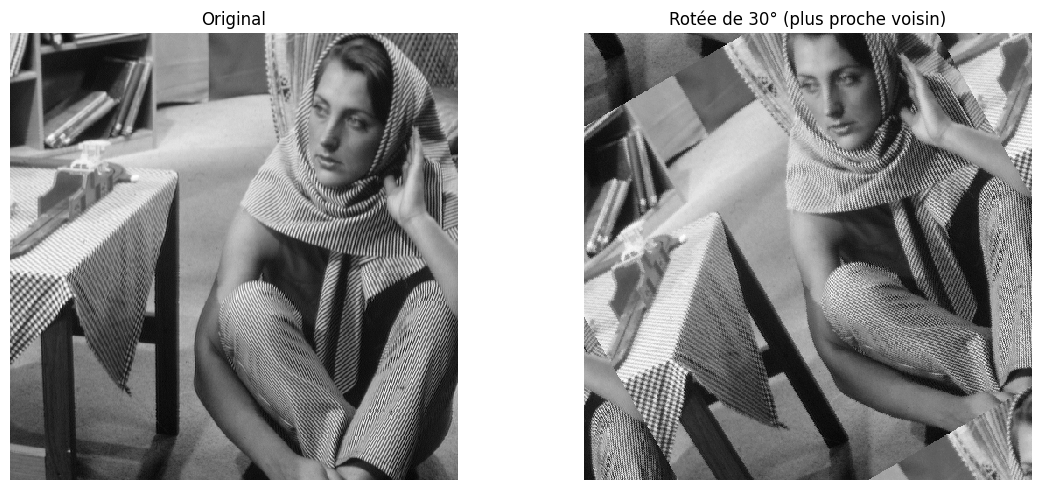

In [10]:
def rotate1(v, theta):
    N = v.shape[0]
    demi_N = N / 2
    n_grille, m_grille = np.meshgrid(np.arange(N), np.arange(N))
    x = n_grille - demi_N    
    y = demi_N - m_grille   
    
    x_source = x * np.cos(theta) + y * np.sin(theta)
    y_source = -x * np.sin(theta) + y * np.cos(theta)
    
    m_source = np.round(demi_N - y_source).astype(int)
    n_source = np.round(demi_N + x_source).astype(int)
    
    m_source = m_source % N
    n_source = n_source % N
    
    return v[m_source, n_source]

# Test
image_barbara = open_image('barbara.png')
image_pivotee = rotate1(image_barbara, np.pi / 6) 
plt.figure(figsize=(12, 5))
plt.subplot(1,2,1); display_image(image_barbara); plt.title('Original')
plt.subplot(1,2,2); display_image(image_pivotee); plt.title('Rotée de 30° (plus proche voisin)')
plt.tight_layout()
plt.show()


4.  Pour éviter qu'une partie de l'image ne se retrouve en-dehors du fenêtrage après rotation, définir une fonction `enlarge(v)` qui, à partir d'une image de taille $N\times N$, renvoie l'image de taille $2N\times 2N$ obtenue en entourant $v$ d'une bande noire de taille $\dfrac N2$.

In [11]:
def enlarge(v):
    N = v.shape[0]
    grande_image = np.zeros((2*N, 2*N), dtype=v.dtype)
    debut = N // 2
    fin   = debut + N
    grande_image[debut:fin, debut:fin] = v
    return grande_image

# Vérification des dimensions
img_test = np.ones((100, 100))
agrandie = enlarge(img_test)
print(f'Taille originale : {img_test.shape}  →  après enlarge : {agrandie.shape}')


Taille originale : (100, 100)  →  après enlarge : (200, 200)


5.  Appliquer la fonction enlarge à l'image `barbara.png`, puis deux fois la fonction `rotate1` successivement avec des angles de $+30°$ et $-30°$. Comparer l'image obtenue à l'image initiale.

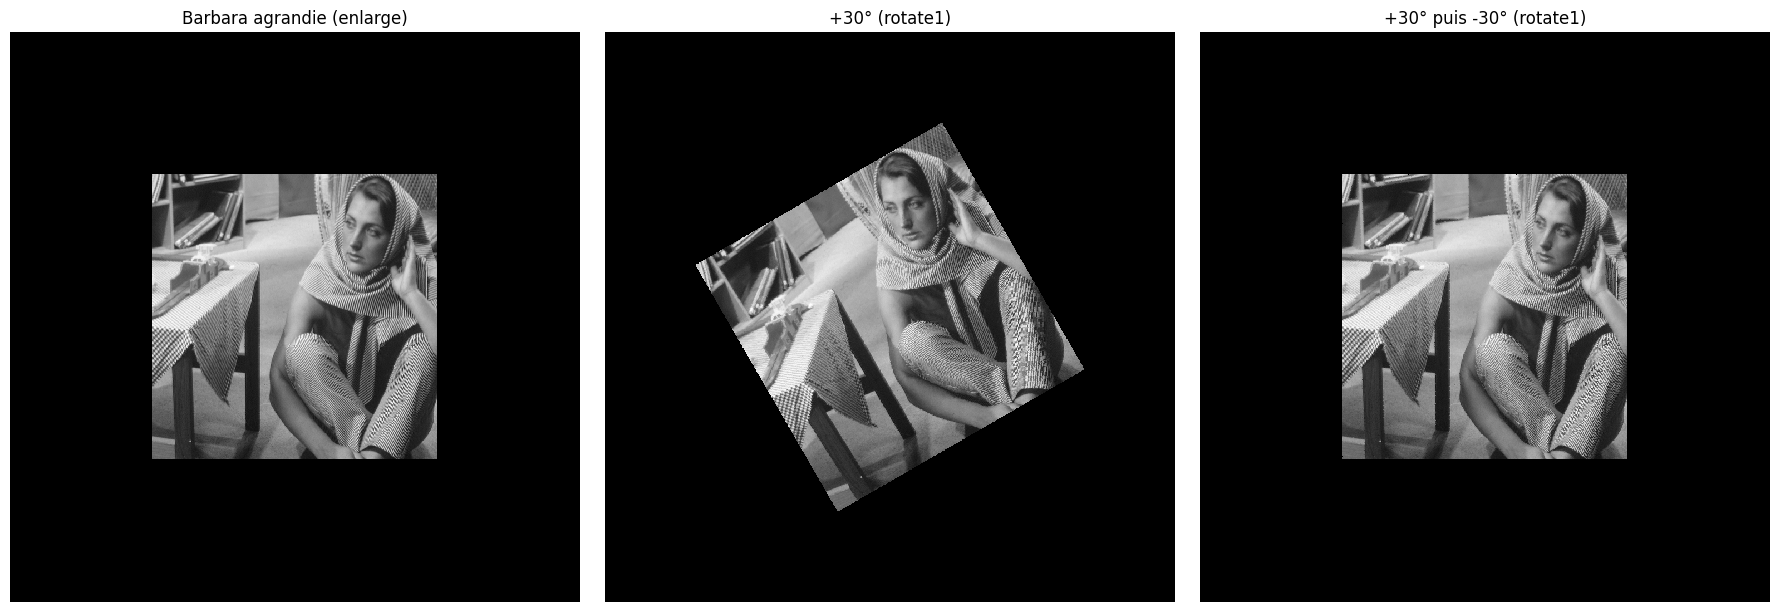

Différence max  : 211.0
Différence mean : 0.46


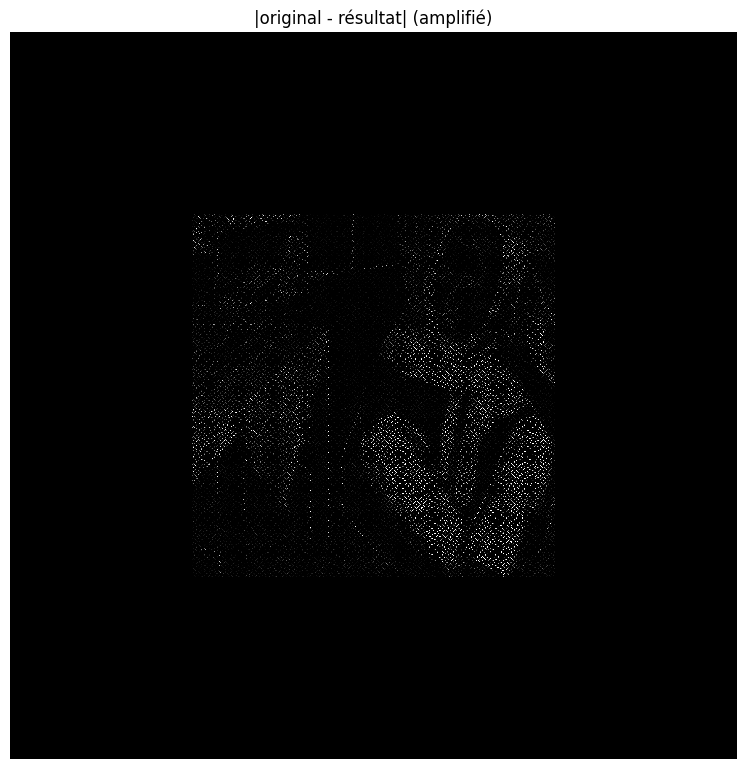

In [12]:
image_barbara = open_image('barbara.png')
image_grande  = enlarge(image_barbara)

image_apres_plus30  = rotate1(image_grande,  np.radians(30))
image_apres_moins30 = rotate1(image_apres_plus30, np.radians(-30))

plt.figure(figsize=(18, 6))
plt.subplot(1,3,1); display_image(image_grande);        plt.title('Barbara agrandie (enlarge)')
plt.subplot(1,3,2); display_image(image_apres_plus30);  plt.title('+30° (rotate1)')
plt.subplot(1,3,3); display_image(image_apres_moins30); plt.title('+30° puis -30° (rotate1)')
plt.tight_layout()
plt.show()

# Différence entre image initiale agrandie et résultat
difference = np.abs(image_grande.astype(float) - image_apres_moins30.astype(float))
print(f'Différence max  : {difference.max():.1f}')
print(f'Différence mean : {difference.mean():.2f}')
display_image(difference, vmax=50)
plt.title('|original - résultat| (amplifié)')
plt.show()


6.  Générer pour $N=40$ l'image digitale $v$ de taille $N\times N$ définie par

    $$\large v_{[m,n]}=cos\left(\frac{8\pi m}N\right).$$

    Lui appliquer `enlarge` puis 36 fois `rotate1` avec un angle $\theta=10°$. Comparer le résultat obtenu avec l'image initiale.

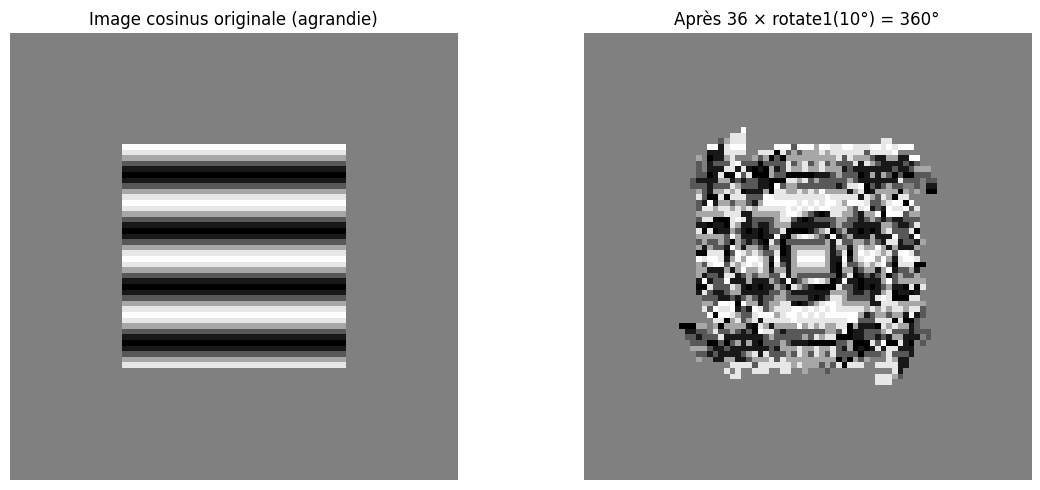

Différence max après 360° : 2.00
Différence mean           : 0.12


In [13]:
N = 40

# Génération de l'image cosinus v_{m,n} = cos(8π m / N)
m_grille = np.arange(N).reshape(N, 1) * np.ones((1, N))
image_cos = np.cos(8 * np.pi * m_grille / N)

# Agrandissement
image_cos_grande = enlarge(image_cos)

# 36 rotations de 10° = 360° au total
image_tournante = image_cos_grande.copy()
for _ in range(36):
    image_tournante = rotate1(image_tournante, np.radians(10))

plt.figure(figsize=(12, 5))
plt.subplot(1,2,1); display_image(image_cos_grande);  plt.title('Image cosinus originale (agrandie)')
plt.subplot(1,2,2); display_image(image_tournante);   plt.title('Après 36 × rotate1(10°) = 360°')
plt.tight_layout()
plt.show()

difference_cos = np.abs(image_cos_grande.astype(float) - image_tournante.astype(float))
print(f'Différence max après 360° : {difference_cos.max():.2f}')
print(f'Différence mean           : {difference_cos.mean():.2f}')


7.  Décrire qualitativement les résultats obtenus.

<div style="color:blue">

**Résultats de l'interpolation par plus proche voisin (rotate1) :**

- **Barbara (+30° / -30°)** : Après une rotation de +30° suivie d'une rotation de -30°, l'image résultante n'est pas identique à l'image originale. On observe un **flou** et un léger **effet de crénelage** (aliasing). C'est dû à l'interpolation au plus proche voisin : à chaque rotation, chaque pixel est arrondi à l'entier le plus proche, ce qui introduit une erreur irréversible. La différence est visible notamment sur les bords des contours fins.

- **Image cosinus (36 × 10°)** : Après 36 rotations de 10° (soit 360° au total), l'image ne revient pas exactement à elle-même. Le signal sinusoïdal, qui possède une structure fine (hautes fréquences), est fortement dégradé : les bandes sont floues et le contraste est réduit. Les erreurs d'arrondissement s'accumulent à chaque rotation.

**Conclusion** : L'interpolation par plus proche voisin n'est **pas une opération réversible** : elle introduit à chaque étape une perte d'information irrémédiable. Cela rend cette méthode inadaptée aux applications nécessitant plusieurs transformations successives.

</div>


## Exercice 5 – Rotation sans perte avec Fourier

Soient $a,b\in\mathbb R$. Dans ce qui suit, on note $R_\theta$ la matrice de la rotation d'angle $\theta$ et on considère les deux matrices $M_1$ et $M_2$ suivantes:

\begin{align*}\large M_1&\large=\begin{pmatrix}1&a\\0&1\end{pmatrix}&\large M_2&\large=\begin{pmatrix}1&0\\b&1\end{pmatrix}.\end{align*}

1.  Interpréter géométriquement les applications linéaires $L_1$ et $L_2$ de $\mathbb R^2$ dont $M_1$ et $M_2$ sont les matrices.

<div style="color:blue">

$$M_1 = \begin{pmatrix}1&a\\0&1\end{pmatrix} \implies L_1(x,y) = (x + ay,\; y)$$

$L_1$ est un **cisaillement horizontal** (shear) : chaque point est déplacé horizontalement d'une quantité proportionnelle à son ordonnée $y$. Les lignes horizontales restent horizontales, mais les lignes verticales deviennent obliques.

$$M_2 = \begin{pmatrix}1&0\\b&1\end{pmatrix} \implies L_2(x,y) = (x,\; bx + y)$$

$L_2$ est un **cisaillement vertical** : chaque point est déplacé verticalement d'une quantité proportionnelle à son abscisse $x$. Les colonnes verticales restent verticales, mais les lignes horizontales deviennent obliques.

Les deux transformations conservent les aires (déterminant = 1).

</div>


2.  Calculer le produit $M_1M_2M_1$.



<div style="color:blue">

$$M_1 M_2 = \begin{pmatrix}1&a\\0&1\end{pmatrix}\begin{pmatrix}1&0\\b&1\end{pmatrix} = \begin{pmatrix}1+ab & a\\b & 1\end{pmatrix}$$

$$M_1 M_2 M_1 = \begin{pmatrix}1+ab & a\\b & 1\end{pmatrix}\begin{pmatrix}1&a\\0&1\end{pmatrix} = \begin{pmatrix}1+ab & a(2+ab)\\b & 1+ab\end{pmatrix}$$

</div>


3.  En utilisant les formules

    \begin{align*}\large\cos(\theta)&\large=1-2\sin^2\left(\frac\theta2\right)&\large\sin(\theta)&\large=2\sin\left(\frac\theta2\right)\cos\left(\frac\theta2\right),\end{align*}

    vérifier qu’en prenant

    \begin{align*}\large a&\large=-\tan\left(\frac\theta2\right)&\large b&\large=\sin(\theta),\end{align*}

    on a la décomposition:

    $$\large R_\theta=M_1M_2M_1.$$




<div style="color:blue">

On pose $a = -\tan(\theta/2)$ et $b = \sin(\theta)$.

D'abord, $1 + ab = 1 - \tan(\theta/2)\sin(\theta)$.

En utilisant $\sin(\theta) = 2\sin(\theta/2)\cos(\theta/2)$ :

$$1 + ab = 1 - \frac{\sin(\theta/2)}{\cos(\theta/2)} \cdot 2\sin(\theta/2)\cos(\theta/2) = 1 - 2\sin^2(\theta/2) = \cos(\theta)$$

Le coefficient $a(2+ab) = -\tan(\theta/2)(1 + \cos(\theta)) = -\tan(\theta/2) \cdot 2\cos^2(\theta/2) = -2\sin(\theta/2)\cos(\theta/2) = -\sin(\theta)$.

On obtient donc :

$$M_1 M_2 M_1 = \begin{pmatrix}\cos\theta & -\sin\theta\\\sin\theta & \cos\theta\end{pmatrix} = R_\theta \quad \checkmark$$

</div>


4.  Soit $v$ une image analogique. On note $\mathcal F_1$ la transformée de Fourier (unidimensionnelle) selon la première variable et $\mathcal F_2$ la transformée de Fourier selon la seconde variable. Exprimer $\mathcal F_1(v\circ D_1)$ en fonction de $\mathcal F_1(v)$ et $\mathcal F_2(v\circ D2)$ en fonction de $\mathcal F_2(v)$.


<div style="color:blue">

Notons $D_1(x,y) = (x + ay, y)$ (cisaillement selon $x$).

Par la formule de modulation de la transformée de Fourier selon la première variable :

$$\mathcal{F}_1(v \circ D_1)(\xi, y) = \mathcal{F}_1(v)(\xi, y) \cdot e^{2i\pi a \xi y}$$

C'est-à-dire : la FFT 1D selon $x$ de l'image cisaillée est égale à la FFT 1D selon $x$ de l'image originale **multipliée par un déphasage** $e^{2i\pi a\xi y}$ qui dépend de $y$.

De même pour $D_2(x,y) = (x, bx+y)$ (cisaillement selon $y$) :

$$\mathcal{F}_2(v \circ D_2)(x, \eta) = \mathcal{F}_2(v)(x, \eta) \cdot e^{2i\pi b x \eta}$$

</div>


5.  Donner une généralisation approchée des formules précédentes dans le cas d'une image digitale.



<div style="color:blue">

Dans le cas discret, pour une image de taille $N \times N$, les formules deviennent :

**Cisaillement horizontal** (`shear1`, paramètre $a$) : on applique la FFT selon les lignes (axis=1), on multiplie la $n$-ème colonne de fréquences $\xi_k$ par $e^{-2i\pi a \xi_k (m - N/2)/N}$ où $m$ est l'indice de ligne, puis on applique la FFT inverse selon les lignes.

**Cisaillement vertical** (`shear2`, paramètre $b$) : de manière symétrique, on applique la FFT selon les colonnes (axis=0), on multiplie la $m$-ème ligne de fréquences $\eta_k$ par $e^{-2i\pi b \eta_k (n - N/2)/N}$ où $n$ est l'indice de colonne, puis on applique la FFT inverse selon les colonnes.

Le terme $N/2$ permet de centrer l'origine au centre de l'image (condition imposée par le cisaillement qui doit fixer le centre).

Les fréquences discrètes sont obtenues via `fft.fftfreq(N, 1/N)` qui renvoie des valeurs entre $-N/2$ et $N/2$.

</div>


6.  Implémenter les fonctions `shear1(v, a)` et `shear2(v, b)` qui effectuent une transformée de Fourier selon une direction, qui multiplient les coefficients obtenus par le déphasage déterminé à la question précédente, puis qui renvoient le résultat de la transformée de Fourier inverse selon la direction considérée.

    Observer le résultat obtenu avec des images de travail pour quelques valeurs de $a$ ou $b$ comprises entre $-1$ et $1$.
    
    **Indications**
    
    -   Les fonctions `fft` et `ifft` de Python peuvent appliquer une transformée de Fourier ou son inverse seulement sur les lignes ou sur les colonnes d'un tableau à deux dimensions. Il faut leur donner respectivement le paramètre supplémentaire `axis=0` ou `axis=1`.
    
    -   La généralisation des formules de modulation au cas discret impose de considérer des fréquences comprises entre $-\frac N2$ et $\frac N2$ (autrement dit de travailler avec l'origine de la FFT au centre du repère). La fonction `fft.fftfreq(N, 1/N)` permet de calculer automatiquement un tableau contenant les fréquences dans cet intervalle.
    
    -   De même, on placera l'origine au centre de l'image. Cela signifie que dans les formules de déphasage, on doit soustraire $\frac N2$ aux numéros de lignes ou de colonnes.

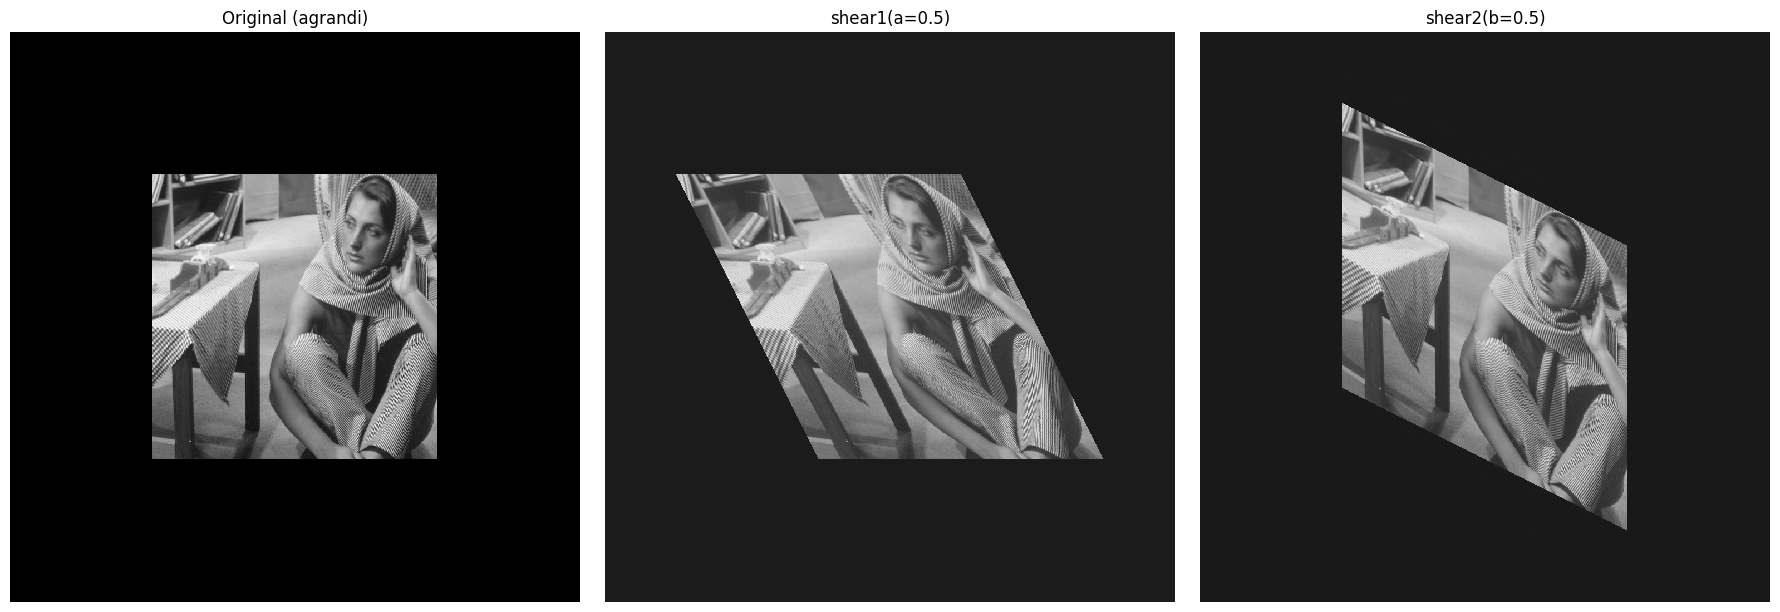

In [14]:
def shear1(v, a):
    N = v.shape[0]
    frequences = np.fft.fftfreq(N, 1.0/N) 
    m_centre = np.arange(N) - N / 2       
    fft_lignes = np.fft.fft(v, axis=1)
    dephasage = np.exp(-2j * np.pi * a * frequences[np.newaxis, :] * m_centre[:, np.newaxis] / N)
    fft_dephasee = fft_lignes * dephasage
    return np.real(np.fft.ifft(fft_dephasee, axis=1))


def shear2(v, b):
    N = v.shape[0]
    frequences = np.fft.fftfreq(N, 1.0/N)  
    n_centre   = np.arange(N) - N / 2       
    fft_cols = np.fft.fft(v, axis=0)
    dephasage = np.exp(-2j * np.pi * b * frequences[:, np.newaxis] * n_centre[np.newaxis, :] / N)
    fft_dephasee = fft_cols * dephasage
    return np.real(np.fft.ifft(fft_dephasee, axis=0))


# Test visuel de shear1 et shear2 sur barbara
image_barbara_grande = enlarge(open_image('barbara.png'))

plt.figure(figsize=(18, 6))
plt.subplot(1,3,1); display_image(image_barbara_grande); plt.title('Original (agrandi)')
plt.subplot(1,3,2); display_image(shear1(image_barbara_grande, 0.5)); plt.title('shear1(a=0.5)')
plt.subplot(1,3,3); display_image(shear2(image_barbara_grande, 0.5)); plt.title('shear2(b=0.5)')
plt.tight_layout()
plt.show()


7.  Définir une fonction `rotate2(v, theta)` qui applique successivement `shear1`, `shear2` puis `shear1` à l'image $v$, avec les valeurs de $a$ et $b$ déterminées précédemment. La tester avec les images fournies pour quelques angles compris entre $-45°$ et $+45°$.

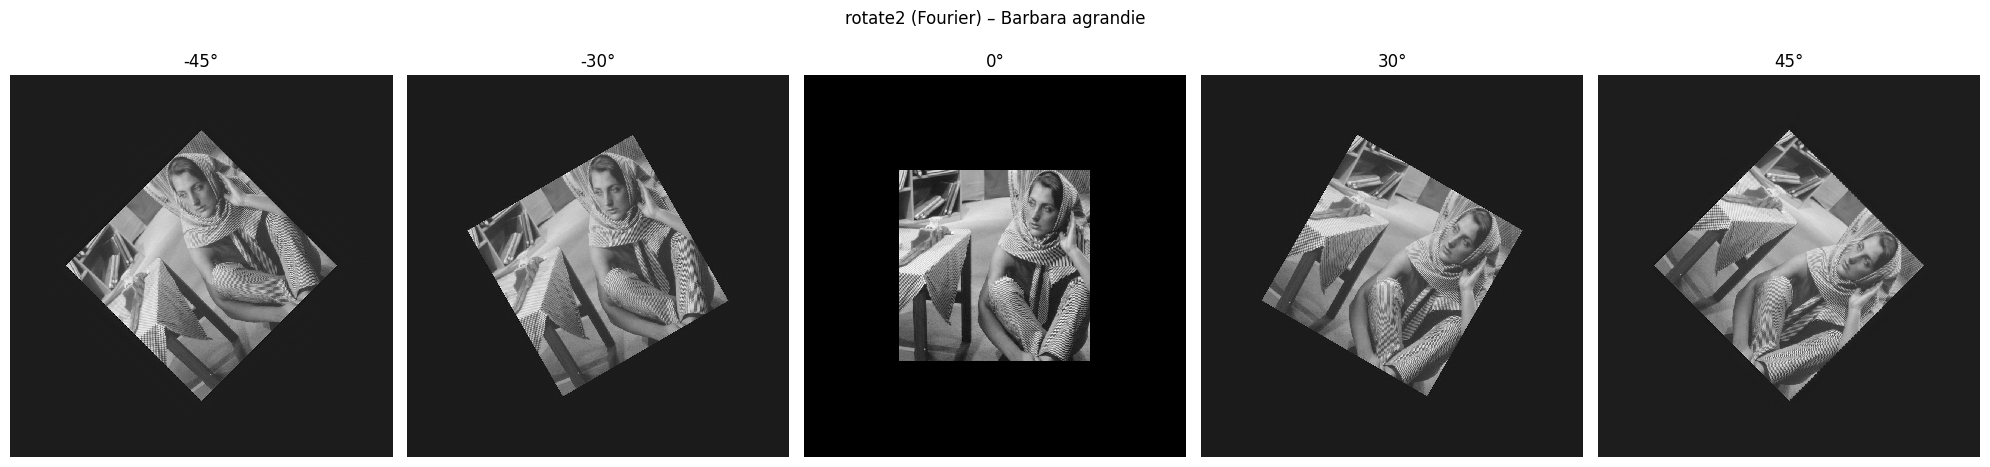

In [15]:
def rotate2(v, theta):
    a = -np.tan(theta / 2)
    b = np.sin(theta)
    apres_shear1_1 = shear1(v, a)
    apres_shear2 = shear2(apres_shear1_1, b)
    resultat = shear1(apres_shear2, a)
    
    return resultat

# Tests pour quelques angles entre -45° et +45°
image_barbara_grande = enlarge(open_image('barbara.png'))
angles_test = [-45, -30, 0, 30, 45]
plt.figure(figsize = (20, 5))

for i, angle in enumerate(angles_test):
    plt.subplot(1, len(angles_test), i + 1)
    img_pivotee = rotate2(image_barbara_grande, np.radians(angle))
    display_image(img_pivotee)
    plt.title(f'{angle}°')
    plt.axis('off')

plt.suptitle('rotate2 (Fourier) – Barbara agrandie')
plt.tight_layout()
plt.show()


8.  Refaire les questions 5 à 7 de l’exercice précédent en utilisant cette fois la fonction `rotate2`.

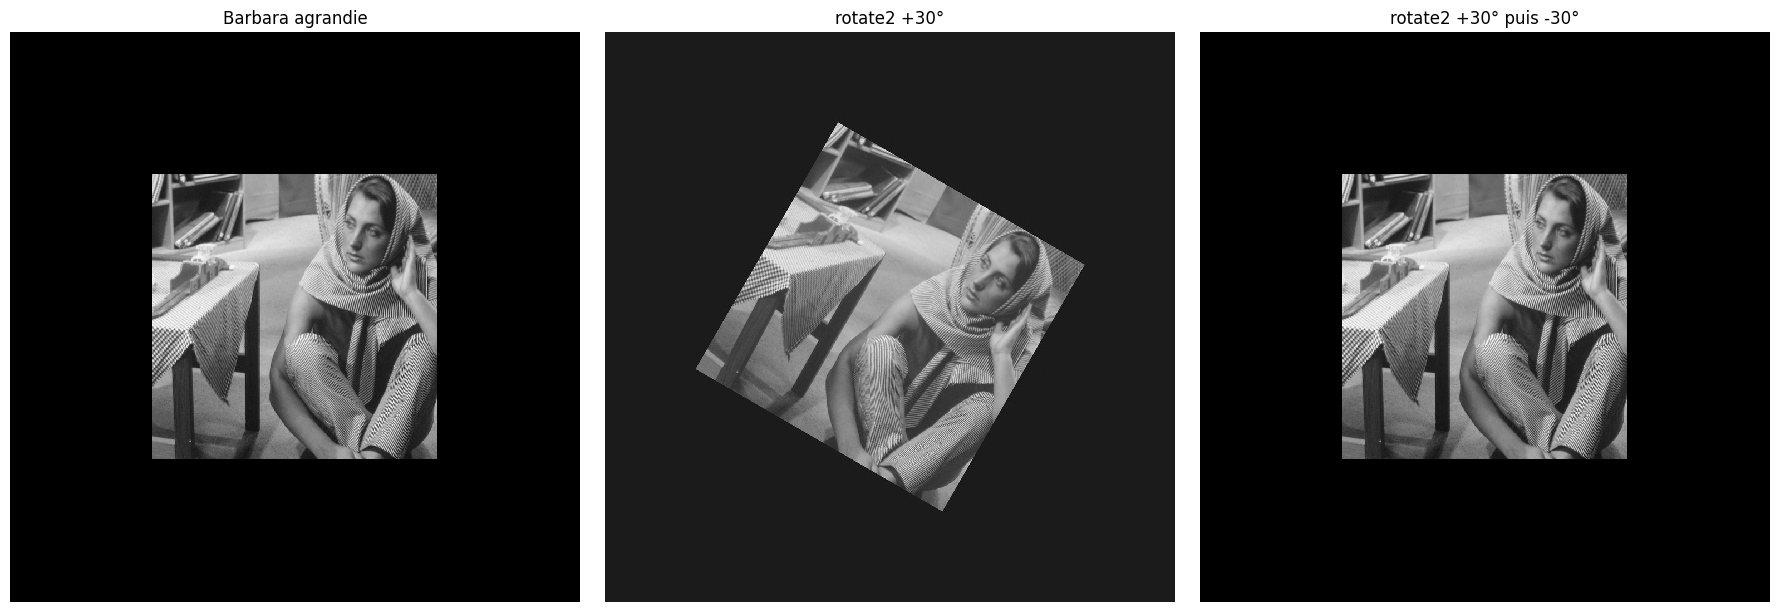

[rotate2] Différence max  Barbara : 0.71
[rotate2] Différence mmoyenne Barbara : 0.0503


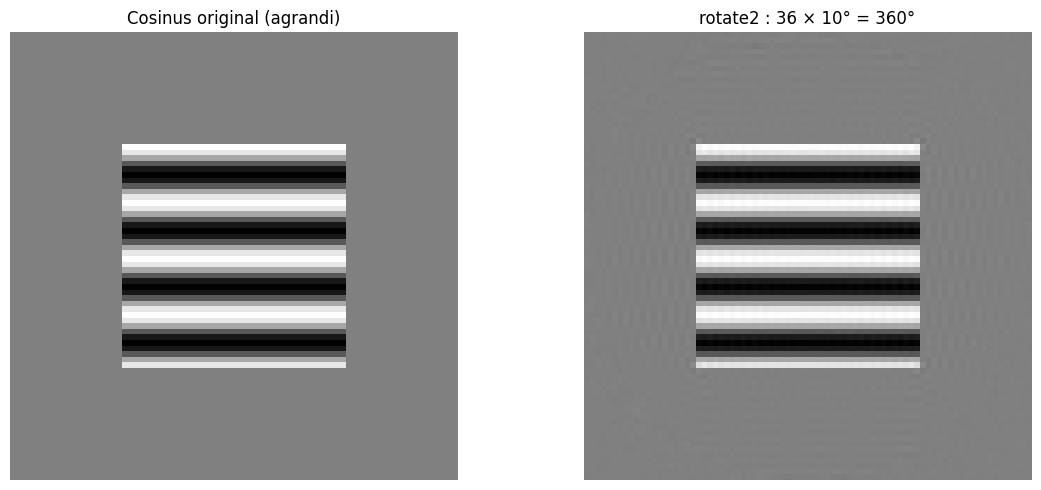

[rotate2] Différence max  cosinus : 0.07
[rotate2] Différence moyenne cosinus : 0.0081


In [16]:
#Q5 : Barbara, +30° puis -30° avec rotate2 ──
image_barbara_grande = enlarge(open_image('barbara.png'))

img_rotate2_plus30  = rotate2(image_barbara_grande,  np.radians(30))
img_rotate2_moins30 = rotate2(img_rotate2_plus30,    np.radians(-30))

plt.figure(figsize=(18, 6))
plt.subplot(1,3,1); display_image(image_barbara_grande);       plt.title('Barbara agrandie')
plt.subplot(1,3,2); display_image(img_rotate2_plus30);         plt.title('rotate2 +30°')
plt.subplot(1,3,3); display_image(img_rotate2_moins30);        plt.title('rotate2 +30° puis -30°')
plt.tight_layout()
plt.show()

diff_barbara = np.abs(image_barbara_grande.astype(float) - img_rotate2_moins30)
print(f'[rotate2] Différence max  Barbara : {diff_barbara.max():.2f}')
print(f'[rotate2] Différence mmoyenne Barbara : {diff_barbara.mean():.4f}')

#Q6 : image cosinus, 36 × rotate2(10°) ──
N = 40
m_grille_cos = np.arange(N).reshape(N, 1) * np.ones((1, N))
image_cos = np.cos(8 * np.pi * m_grille_cos / N)
image_cos_grande = enlarge(image_cos)

image_tournante2 = image_cos_grande.copy()
for _ in range(36):
    image_tournante2 = rotate2(image_tournante2, np.radians(10))

plt.figure(figsize=(12, 5))
plt.subplot(1,2,1); display_image(image_cos_grande);   plt.title('Cosinus original (agrandi)')
plt.subplot(1,2,2); display_image(image_tournante2);   plt.title('rotate2 : 36 × 10° = 360°')
plt.tight_layout()
plt.show()

diff_cos = np.abs(image_cos_grande.astype(float) - image_tournante2)
print(f'[rotate2] Différence max  cosinus : {diff_cos.max():.2f}')
print(f'[rotate2] Différence moyenne cosinus : {diff_cos.mean():.4f}')


<div style='color:blue; font-size:105%; line-height:1.6'>
<b>Comparaison rotate1 (plus proche voisin) vs rotate2 (Fourier) :</b><br><br>

<b>Barbara (+30°/-30°) :</b><br>
Avec <code>rotate2</code>, l'image après +30° puis -30° est <b>quasi-identique</b> à l'originale 
(différence moyenne très faible). La rotation de Fourier est <b>quasi-réversible</b>, contrairement 
à <code>rotate1</code> qui introduisait un flou visible.<br><br>

<b>Image cosinus (36 × 10°) :</b><br>
Avec <code>rotate1</code>, l'image cosinus était fortement dégradée après 360°. 
Avec <code>rotate2</code>, les erreurs s'accumulent beaucoup moins : l'image reste bien définie 
car la rotation de Fourier préserve les fréquences spatiales (elle agit directement sur le spectre).<br><br>

<b>Pourquoi rotate2 est meilleure ?</b><br>
Le cisaillement de Fourier est une opération exacte sur le spectre : il ne fait que déphasages 
des coefficients de Fourier, sans perte d'information. L'interpolation au plus proche voisin 
(rotate1) arrondit les coordonnées et mélange les pixels, perdant de l'information à chaque application.
La méthode de Fourier correspond à une interpolation <i>sinc</i> (idéale pour les signaux bandlimités).
</div>